# Speculative Decoding Tutorial

Speculative decoding is a useful way of accelerating inference in autoregressive models. Introduced less than 4 years ago, it has sparked an active line of research, including the algorithms Medusa and EAGLE. Speculative decoding is now deployed in many production systems, such as TensorRT-LLM and Google Search AI summary.

__Prerequisites__: familiarity with python, probability distributions, and conceptual understanding of how LLMs generate text using tokens

__Level__: advanced undergraduate

__Learning objectives__:
- understanding how the algorithm works using an interactive visualization
- check correctness empirically on a toy data set to see that speculative decoding results in the same probability distribution as the original, slower model
- code a Monte Carlo simulation to check the speed improvement

All commonly used LLMs (Claude, GPT, Gemini, DeepSeek, etc) are *autoregressive*. This means that each token depends on all the tokens that came before it. You cannot compute token 5 until token 4 exists. This serial dependency means that you can't parallelize the generation of tokens.

Speculative decoding dramatically improves performance for autoregressive models.  Rather than generate tokens in parallel (which you can't do), it instead uses a much smaller model to generate multiple tokens faster.  Speculative decoding was introduced in late 2022/early 2023 (Leviathan, et al.; Chen, et al.) as an algorithm to generate the same distribution as the standard approach, but with a concrete walltime improvement.

Since 2023, speculative decoding and variations that build on it (such as Medusa and EAGLE) have become widely used, including in Nvidia's TensorRT-LLM library, Google Search's AI overview, and DeepSeek-v4.

A key contribution of speculative decoding is that it offers a way to accelerate inference **without** changing the model architectures, training procedures, or output distribution.



### References

#### The original speculative decoding papers
- Yaniv Leviathan, Matan Kalman, and Yossi Matias. *Fast Inference from Transformers via Speculative Decoding.* ICML 2023.
- Charlie Chen, Sebastian Borgeaud, Geoffrey Irving, Jean-Baptiste Lespiau, Laurent Sifre, and John Jumper. *Accelerating Large Language Model Decoding with Speculative Sampling.* arXiv preprint arXiv:2302.01318, 2023.


#### Later work
 - Tianle Cai, Yuhong Li, Zhengyang Geng, Hongwu Peng, Jason D. Lee, Deming Chen, and Tri Dao. *Medusa: Simple LLM Inference Acceleration Framework with Multiple Decoding Heads.* ICML 2024.
- Jian Chen, Yesheng Liang, and Zhijian Liu. *DFlash: Block Diffusion for Flash Speculative Decoding.* ICML 2026.
- Yichao Fu, Peter Bailis, Ion Stoica, and Hao Zhang. *Break the Sequential Dependency of LLM Inference Using Lookahead Decoding.* ICML 2024.
- Tanishq Kumar, Tri Dao, and Avner May. *Speculative Speculative Decoding.* ICML 2026.
- Yuhui Li, Fangyun Wei, Chao Zhang, and Hongyang Zhang. *EAGLE: Speculative Sampling Requires Rethinking Feature Uncertainty.* ICML 2024.
- Xin Cheng, Xingkai Yu, Chenze Shao, et al. *DSpark: Confidence-Scheduled Speculative Decoding with Semi-Autoregressive Generation.* arXiv preprint arXiv:2607.05147, 2026.

#### Use in production systems
- Yaniv Leviathan, Matan Kalman, and Yossi Matias. *Looking back at speculative decoding.* Google Research Blog, 2024.
- Anjali Shah, Ashraf Eassa, Carl (Izzy) Putterman, Lalit Vaidya, Jatin Gangani, and Anu Srivastava. *Boost Llama 3.3 70B Inference Throughput 3x with NVIDIA TensorRT-LLM Speculative Decoding.* NVIDIA Developer Blog, December 2024.


## What Speculative Decoding is

### Why standard decoding is slow

At first this may sound too good to be true. How can we just use a smaller model in place of the larger one?  The key insight is understanding the bottleneck for autoregressive models

To process tokens, the model must:
1. Read all its weights from memory (the memory-bandwidth cost)
2. Do the arithmetic on those weights (the compute cost)

The bottleneck is memory-bandwidth. The arithmetic is comparatively cheap. This means that a larger model can do the arithmetic to validate/reject a number of tokens in parallel.

### The core idea of speculative decoding

The weights only get loaded from memory a single time per run, regardless of how many tokens you are applying them to. Reading the weights once lets you do the arithmetic for many tokens at nearly the same cost as for one token. Standard decoding can't take advantage of this; the serial dependency means there is never more than one new token ready to process per sequence. In speculative decoding, there are two models:

- $M_{draft}$: small, cheap model guesses the next several tokens
- $M_{target}$: large model can evaluate every position at once, in a single run, loading its weights once instead of once per token

The large model's parallel run does two things: it both checks the guesses and provides real answer. The guesses are checked left to right and accepted up to the first mistake. At that point the large model supplies the correct token, and everything after the rejection is thrown away, since those guesses were built on a wrong token.

This tutorial will focus on the the original version of speculative decoding, described in the first paper: [Fast Inference from Transformers via Speculative Decoding](https://arxiv.org/abs/2211.17192) (Leviathan, Kalman, & Matias, 2023)

### Visualization of Speculative Decoding

The visualization below can help us get an intuitive sense of what specultive decoding is doing.  I built it using the "How to Solve It" method, a JupyUvi server, and HTMX.

You will first need to install the required libraries from the `requirements.txt` file. Please run the following lines of code to create the visualization.

In [ ]:
from IPython.display import display,Image as IpyImage,Markdown, Video
from pathlib import Path
from fasthtml.jupyter import JupyUvi, HTMX

In [ ]:
# needed in SolveIt since the kernel's cwd is the dialog's folder, but the path setup comes from wherever the server launched
import sys; sys.path.insert(0, str(Path.cwd()))

# reload is necessary if changes have been made to the specdec_viz_implementation module
import importlib, specdec_viz_implementation
importlib.reload(specdec_viz_implementation)

from specdec_viz_implementation import app

In [ ]:
import json, os
PORT = 8000

In [ ]:
# keep the server = JupyUvi(app) line in its own cell, separate from your route definitions — then you can re-run the routes freely without touching the server

server = JupyUvi(app, port=PORT)

In [ ]:
if 'PUBLIC_DOMAINS' in os.environ:  # running in Solveit
    host = json.loads(os.environ['PUBLIC_DOMAINS'])[str(PORT)]
    display(HTMX(path='/viz', host=host, port=443, height=400, link=True))
else:  # plain Jupyter
    display(HTMX(path='/viz', height=400, port=PORT, link=True))

HTML(<a href="https://1117bac99a34df0b4e574ca822f96f69.solveit.pub:443/viz" target="_blank">Open in new tab</a>)

HTML(<iframe src="https://1117bac99a34df0b4e574ca822f96f69.solveit.pub:443/viz" style="width: 100%; height: 400px; border: none;" onload="" allow="accelerometer; autoplay; camera; clipboard-read; clipboard-write; display-capture; encrypted-media; fullscreen; gamepad; geolocation; gyroscope; hid; identity-credentials-get; idle-detection; magnetometer; microphone; midi; payment; picture-in-picture; publickey-credentials-get; screen-wake-lock; serial; usb; web-share; xr-spatial-tracking"></iframe> )

If you run into errors, try stopping the server, and then re-running the above code to start the server and display the HTMX.

In [ ]:
server.stop()

If the visualization does not work for you, here is a recorded version:

In [ ]:
Video("spec_dec_video.mp4", width=700)

Video(spec_dec_video.mp4)

Both in the paper (Figure 1 of Leviathan, et al, shown below) and in the interactive visualization in this tutorial, the colors indicate:
- <strong style="color: #222">Black</strong>: accepted tokens from the previous iteration (each sentence begins with 3 accepted tokens as a seed for future predictions)
- <strong style="color: #888">Grey</strong>: guesses generated by the small $M_{draft}$ model
- <strong style="color: #22a447">Green</strong>: accepted guesses this iteration
- <strong style="color: #d33">Red</strong>: first incorrect guess; it and all guesses after will be thrown out
- <strong style="color: #2878d4">Blue</strong>: token from target model during verification (correct token after rejection, or an extra token if all guesses were accepted)

As well as adding an interactive animation, there are a few differences from the original diagram:

- the standard model is shown directly above to offer a contrast over time
- all the generated tokens are shown, including those that are rejected, whereas the paper shows only up until the first rejected guess
- each step consists of 2 clicks of the "next" button, in order to break down the proposal vs. the acceptance
- labels indicate how the speculative decoding line alternates between steps of $M_{draft}$ **guessing** ($M_{draft}$ is the small, fast model) and $M_{target}$ **verifying** ($M_{target}$ is the large, slow model).  Since speculative decoding gets 1-5 tokens right at a time, it moves ahead much quicker than the standard decoding model.

Things to notice about speculative decoding from the visualization:
- the number of accepted guesses varies.  here, it can be anywhere from 0 to 5
- once a guess is rejected, all the guesses (from the same iteration) after it are rejected as well
- even in the case where all the guesses are rejected, the larger model still provides the correct answer while validating, so we don't lose time compared to the standard approach

Note that standard token generalization is done in a single step. The reason we have to push "Next" twice for each step is to keep the number of iterations consistent when pictured alongside speculative decoding.

To find out more about how the speculative decoding demo works, design choices we made, or to modify it yourself, please check out the `specdec-viz-implementation.ipynb` dialog in this folder.  It is built using HTMX, which is a rather straightforward and simple alternative to a javascript framework.

The visualization in this section was inspired directly from Figure 1 of [Fast Inference from Transformers via Speculative Decoding](https://arxiv.org/abs/2211.17192):

![Figure 1 from Leviathan 2023, et al](fig1-leviathan.jpg){width=350}

### Guarantees and trade-offs

Each step yields a variable number of tokens: many when the text is predictable and the draft model guesses well, just one when it guesses poorly. Even in the worst case, every call to the large, slow, target model produces at least one token.

Two properties make speculative decoding work. First, the output distribution is proven to be identical to running the large model alone. 

Second, the smaller model is much, much faster, limiting the cost of excess computation. For instance, in the paper the computational cost of the draft model is 5% that of the cost of memory bandwidth for the larger model. While it is theoretically possible for speculative decoding to be slower than the standard approach (in a worst case where all the guesses are rejected), even then it would only add a small amount of time on.

Nothing else about the models changes: speculative decoding does not require any retraining nor a different architecture.

## Understanding the Algorithm / How it works

One defining aspect of a language model is the probability distribution for which different tokens are generated.  For speculative decoding to be a useful substitute for standard decoding, we need it to result in tokens with the same probability distribution as our original model. 

- $q(x)$ — probability distribution over the vocabulary for the next token, from the *small model* $M_{draft}$
- $p(x)$ — probability distribution over the vocabulary for the next token, from the *large target model* $M_{target}$

Since our language models are *autoregressive*, these distributions depend on all the previous tokens that have been validated.

Seeing the Speculative Decoding Algorithm written out in code on a toy data set can help illustrate that it works.   Before we get to the algorithm, let's first generate some toy data to use.  Our goal here isn't to offer the formal proof from the paper, but hopefully to offer some intuition that it does work (and that alternate variations don't).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
vocab = ['the', 'a', 'dog', 'cat', 'ran', 'sat']
logits = np.array([2.5, 1.8, 0.3, 2.0, 1.0, 0.2])
def softmax(z): e = np.exp(z - z.max()); return e/e.sum()
p = softmax(logits / 0.7)   # sharper  -> target
q = softmax(logits / 1.5)   # flatter  -> draft

We are generating toy values for p and q that are in line with properties we might see in real problems.

- Dividing by a temperature < 1 gives softmax a sharper, more certain distribution, which is what a target model $M_{target}$ would likely have.
- Dividing by a temperature > 1 gives softmax a flatter, more uncertain distribution, which is what a draft model $M_{draft}$ would likely have.

A simple plot shows the two different distributions:

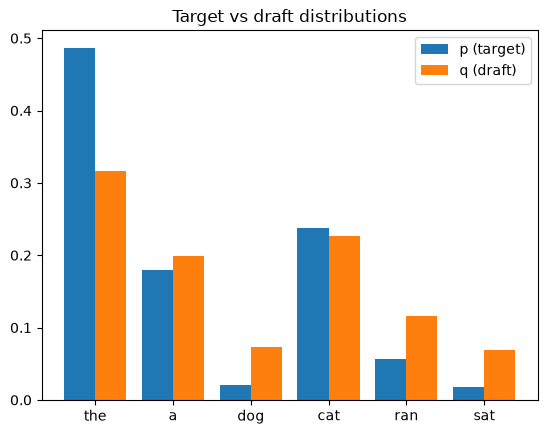

In [ ]:
x = np.arange(len(vocab))
plt.bar(x-0.2, p, 0.4, label='p (target)')
plt.bar(x+0.2, q, 0.4, label='q (draft)')
plt.xticks(x, vocab); plt.legend(); plt.title('Target vs draft distributions');

This is the algorithm for Speculative Sampling.  The rule for each token is:

1. Small/cheap model $M_{draft}$ proposes a token $i \sim q$
2. Draw $r \sim U(0,1)$
3. **Accept** if $r \le \frac{p_{i}}{q_{i}}$ (always accept when $p_{i} \ge q_{i}$, since the ratio is $\ge 1$)
4. **Reject** otherwise, and resample from the residual $p' = \text{norm}(\max(0, p - q))$

Tokens that are over-proposed by $q$ are the ones that will be rejected.  Looking at the distributions, above, we don't have to worry about $q$ proposing "the" or "cat" too much.  In fact, we can accept "the" and "cat" every time $q$ proposes them without overshooting the distribution for $p$.  This is what the step of accepting the token if $r \le \frac{p_{i}}{q_{i}}$ is about.

However, $q$ proposes some words too often and we could overshoot the distribution of $p$. We are at risk of ending up with too many occurrences of "a", "dog", "ran", and "sat" if we are using $q$ to try to achieve the same distribution as $p$. 
This is why we reject and resample from a different distribution if $r \gt \frac{p_{i}}{q_{i}}$.

Below is what this looks like in code:

In [ ]:
def spec_sample(p, q, rng):
    i = rng.choice(len(q), p=q)        # draft proposes
    r = rng.random()
    if r <= p[i]/q[i]: return i        # accept
    resid = np.maximum(0, p - q)       # residual
    resid = resid/resid.sum()          # normalize
    return rng.choice(len(p), p=resid) # resample

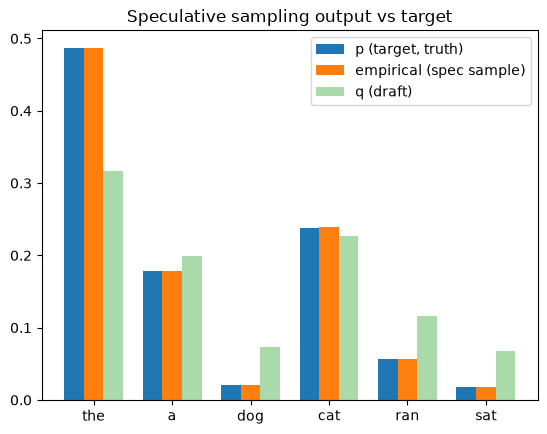

In [ ]:
N = 100_000
samples = np.array([spec_sample(p, q, rng) for _ in range(N)])
emp = np.bincount(samples, minlength=len(p)) / N

x = np.arange(len(vocab))
w = 0.25
plt.bar(x-w, p, w, label='p (target, truth)')
plt.bar(x, emp, w, label='empirical (spec sample)')
plt.bar(x+w, q, w, label='q (draft)', alpha=0.4)
plt.xticks(x, vocab); plt.legend(); plt.title('Speculative sampling output vs target');

### Two ways to break the algorithm

How do we know that our process of resampling from the residual was necessary?  Would we have ended up approximating the distribution of p regardless?  We can "break" the algorithm below, and see that, no, using a different resampling approach gives us the wrong distribution.  This isn't the formal mathematical proof of the paper, but it is a clear visual.

We deliberately break the sampler in two ways and watch the histogram depart from our target distribution p.

- Break A: after rejection, resample from plain p instead of the residual
- Break B: always accept (skip the rejection step entirely)

Let's try resampling just from plain \(p\) instead of from the residual.

In [ ]:
def spec_sample_breakA(p, q, rng):
    i = rng.choice(len(q), p=q)
    r = rng.random()
    if r <= p[i]/q[i]: return i
    return rng.choice(len(p), p=p)  # BUG: resample from p, not residual

Or let's just use q and never reject the tokens it proposes.

In [ ]:
def spec_sample_breakB(p, q, rng):
    i = rng.choice(len(q), p=q)
    return i  # BUG: always keep the draft's proposal

Both of these alternate approaches fail, as you can see in the plot below.  The algorithm proposed (and proven) in the paper is the correct way to go!

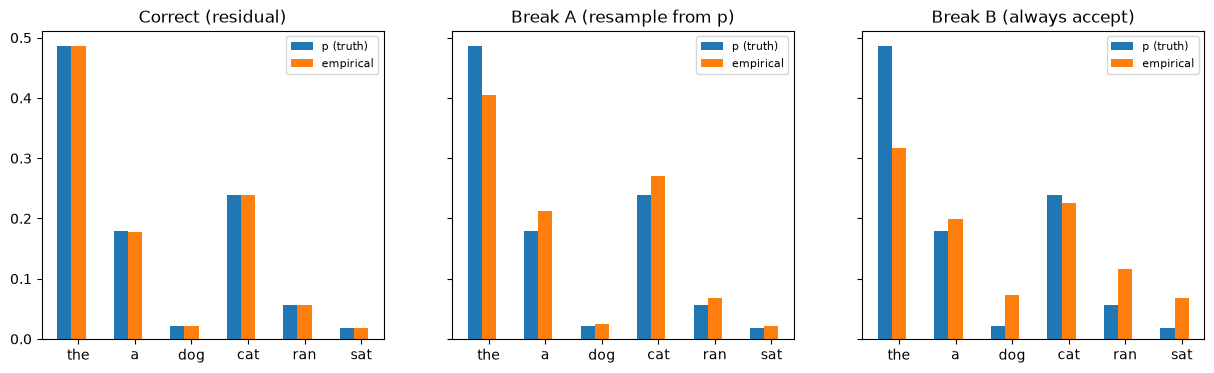

In [ ]:
N = 100_000
samplesA = np.array([spec_sample_breakA(p, q, rng) for _ in range(N)])
samplesB = np.array([spec_sample_breakB(p, q, rng) for _ in range(N)])
empA = np.bincount(samplesA, minlength=len(p)) / N
empB = np.bincount(samplesB, minlength=len(p)) / N

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, emp, title in zip(axes, [emp, empA, empB],
    ['Correct (residual)', 'Break A (resample from p)', 'Break B (always accept)']):
    ax.bar(x-w, p, w, label='p (truth)')
    ax.bar(x, emp, w, label='empirical')
    ax.set_xticks(x); ax.set_xticklabels(vocab)
    ax.set_title(title); ax.legend(fontsize=8)

### The overlap between p and q

The below graphs illustrate the overlap between the 2 distributions, and how setting the residual to \(p - min(p, q)\) gets us to our target distribution \(p\)

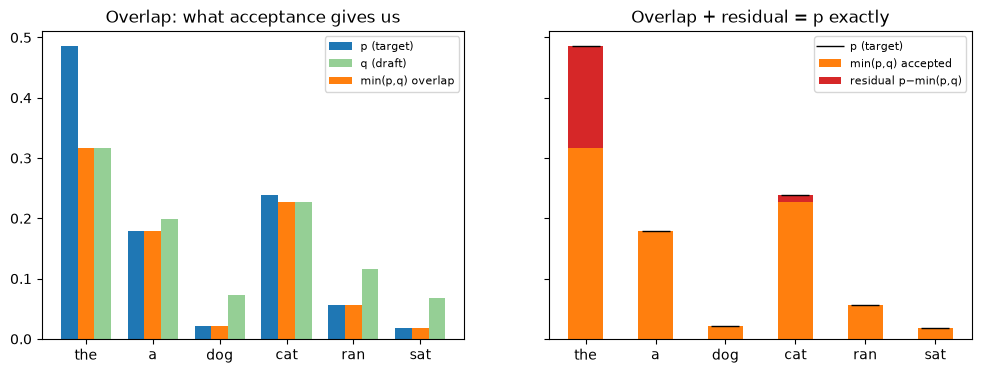

In [ ]:
overlap = np.minimum(p, q)
resid = p - overlap

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].bar(x-w, p, w, label='p (target)')
axes[0].bar(x+w, q, w, label='q (draft)', color='tab:green', alpha=0.5)
axes[0].bar(x, overlap, w, label='min(p,q) overlap', color='tab:orange')
axes[0].set_xticks(x); axes[0].set_xticklabels(vocab)
axes[0].set_title('Overlap: what acceptance gives us'); axes[0].legend(fontsize=8)

axes[1].bar(x, overlap, 0.5, label='min(p,q) accepted', color='tab:orange')
axes[1].bar(x, resid, 0.5, bottom=overlap, label='residual p−min(p,q)', color='tab:red')
axes[1].plot(x, p, 'k_', markersize=20, label='p (target)')
axes[1].set_xticks(x); axes[1].set_xticklabels(vocab)
axes[1].set_title('Overlap + residual = p exactly'); axes[1].legend(fontsize=8)

Acceptance contributes exactly $\min(p,q)$ for each token: the draft proposes at rate $q$, and survival at rate $\min(1, p/q)$ trims that to $\min(p,q)$. The residual $p - \min(p,q)$ is nonzero where $q$ under-proposes. Resampling from the residual supplies the shortfall in order to sum up to $p$.

The broken variants fail because each mishandles one piece. Break B (always accept) never trims, so over-proposed tokens like "dog" and "sat" stay at $q$'s inflated rates. Break A rejects correctly but spreads replacements over all of $p$, double-counting tokens that were already at full quota.

The total orange area, $\sum_{x} \min(p(x), q(x))$, is the overall acceptance rate — the paper calls it $\alpha$. The more the two distributions overlap, the more guesses survive.  $\alpha$ is the key to how much of a speedup speculative decoding offers.

## Time Speed Up

The paper offers mathematical results related to how long it takes to run speculative decoding.

It gives us a formula for the expected tokens per iteration.  This depends on:
- $\gamma$: the number of draft tokens per iteration
- $\alpha = E[\sum_{x} \min(p(x), q(x))]$: how close the distributions $p$ and $q$ are, a measure of the quality of the draft distribution $q$

The paper assumes each draft token behaves as an independent $\alpha$-weighted coin.

Expected tokens per iteration: $E(\#\text{tokens}) = \frac{1-\alpha^{\gamma+1}}{1-\alpha}$ 

We can create a simple Monte Carlo simulator to check if this formula holds for different values of $\alpha$ and $\gamma$.  The below is a simulation of how many tokens will be accepted for each iteration.

We generate $\gamma$ tokens, and the probability that each token is the probability that each token is accepted is $\alpha$.  For each set of tokens (one iteration), we only keep tokens up until the first rejected one.

In [ ]:
import numpy as np

rng = np.random.default_rng(42)

def step_tokens(alpha, gamma, rng):
    # Generate an array of individual flips
    flips = rng.random(gamma) < alpha
    ans = np.argmax(~flips)
    # if all are true, argmax returns 0
    if ans == 0 and flips[0]:
        ans = len(flips)
    return ans + 1  # accepted draft tokens, plus one token from target model

Now, we can plug in some of the numbers shared in the paper.  For instance, let's use $\alpha=0.8$ and $\gamma = 7$.  Looking at Figure 2, the expected number of tokens per iteration is a bit higher than 4.


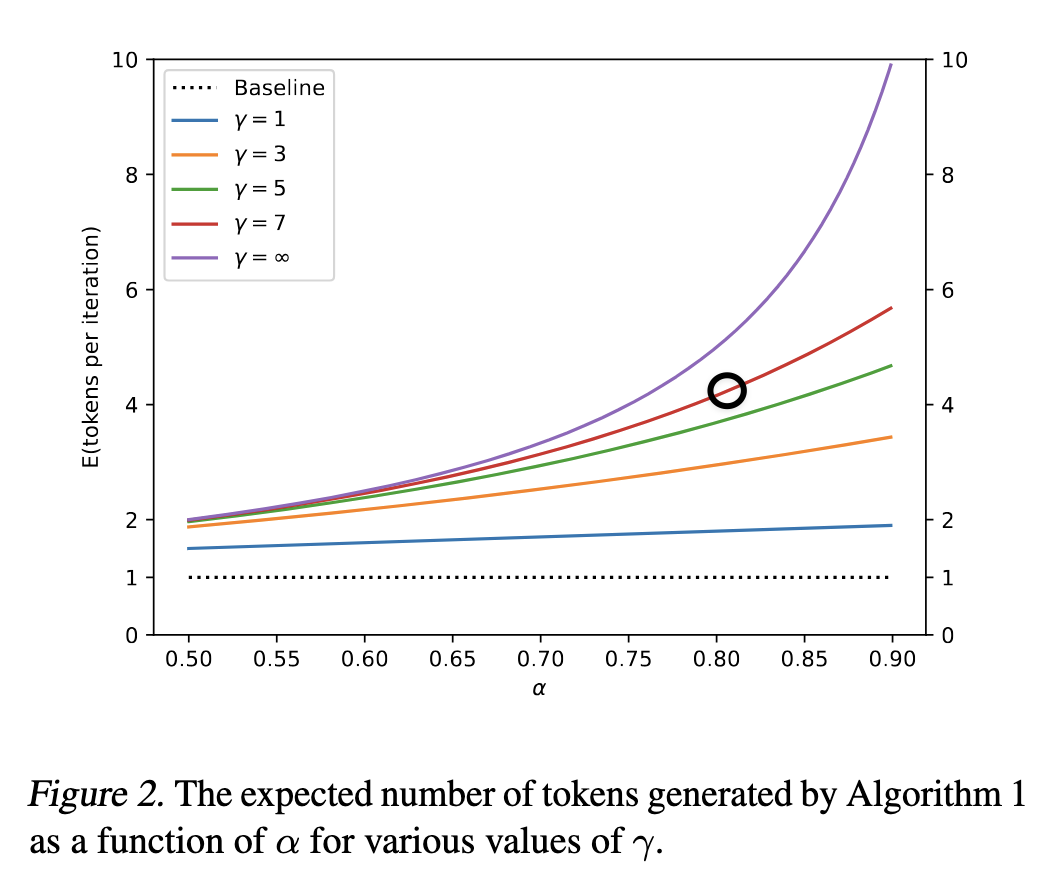

In [ ]:
N = 100_000
alpha, gamma = 0.8, 7

test = np.array([step_tokens(alpha, gamma, rng) for _ in range(N)])
expected = (1 - alpha**(gamma+1)) / (1 - alpha)

expected, test.mean().item()

(4.161139200000001, 4.16528)

The Monte Carlo simulation gives a similar answer to the formula.

An even more useful result is to know how much of a walltime speedup will result from speculative decoding.  We only need one additional piece of information to calculate this:
- $c$: the ratio of the *time for a single run of $M_{draft}$* to the *time for a single run of $M_{target}$* — i.e., how cheap the draft model is relative to the target

This will typically be quite small, 2%-10% (0.02-0.10).  Dividing the expected number of tokens by $(1 + \gamma * c)$ will give us the speedup.

$$\text{speedup}(\gamma) = \frac{1-\alpha^{\gamma+1}}{(1-\alpha)(\gamma c + 1)}$$

There is a tension between $\alpha$ and $c$.  You will see a bigger speedup when the $M_{draft}$ distribution is closer to $M_{target}$ (higher $\alpha$) and when the cost coefficient is smaller ($M_{draft}$ takes a smaller fraction of time).  However, creating a more accurate $M_{draft}$ will typically increase both $\alpha$ and $c$.

### Exercise

Try writing `race(alpha, c, gamma, T, rng)` to return an array of arrival times for speculative decoding, the time at which each of the first T tokens is done. You will need to use the `step_tokens` method from above.

Since $c$ is based on a percentage of how fast $M_{draft}$ is compared to $M_{target}$, time has been normalized such that 1 = $M_{target}$. Thus, in baseline standard decoding, each token t arrives at time t.
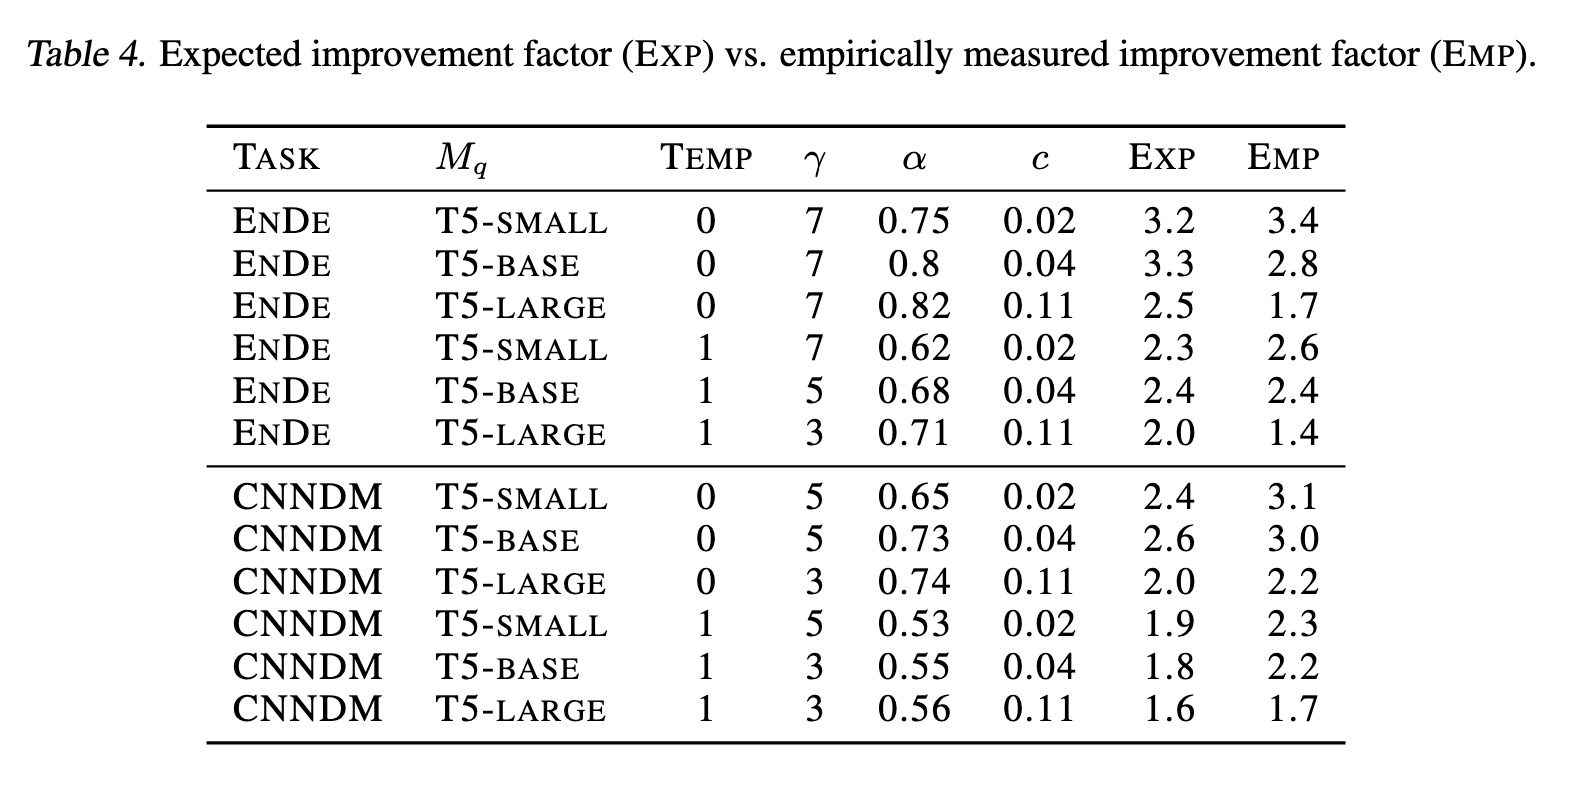

The method `race` raises `NotImplementedError` until you fill it in, and the plot after it needs your answer.

In [ ]:
def race(alpha, c, gamma, T, rng):
    ## Exercise: fill this in
    raise NotImplementedError("Exercise: return arrival times for the first T tokens")

T = 100_000
alpha = 0.75
c = 0.02
gamma = 7

times = race(alpha, c, gamma, T, rng)

You are now ready to plot both methods, with time on x, tokens on y. 

In [ ]:
std = np.arange(1, T+1)

plt.plot(times, std, label='speculative')
plt.plot(std, std, label='standard')
plt.xlabel('time'); plt.ylabel('completed tokens'); plt.legend();

Check your answer against the first row of Table 4 from the paper, which listed both expected and empirical speedups for models translating English to German (EnDe) and text summarization (CNNDM).

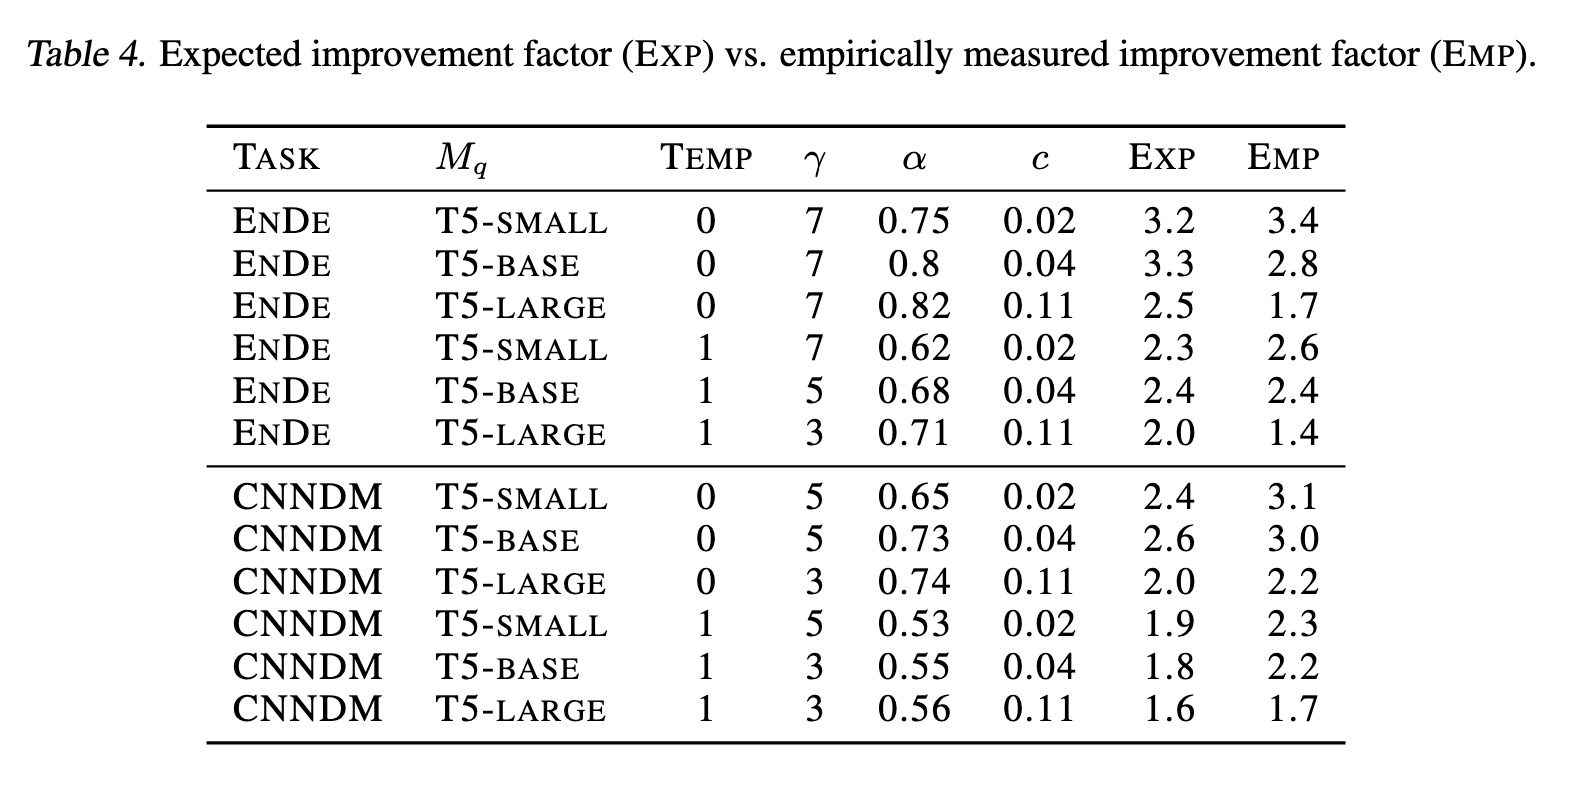